# Chapter 5: The Mechanics of Learning

## Creating a Regresion Model to Inturpter the Reading of a Thermometer with no Units

### Collecting Data
- Collect temp. measuments in deg C., along with the corresp. measuments from the thermometer

In [5]:
import torch

# Measured Temp in C
t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]

# Thermometer readings (unknown Units)
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]

t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)

### Creating a Very Simple (Linear) Model with 2 param (Weights and Biases)

- A model is a mathmatical function with (lots of) parameters: weights and biases, that fit your input (data) to the desired output (data) \
  --> It "Learns" to do this by "training" - Updating/changing model parameters until the function/network maps input to the ground truth (desired output).
- Weight: The weight tells us how much a given input influences the output \
  --> The value you multiply your data by (to fit the line of best fit)
- Bias: The bias is what the output would be if all
inputs were zero. \
-->The value you add to your data (to fit the line of best fit)
- Loss Function: Function that computes a single numerical value, indicating the diffrence (or loss) between model prediction and ground truth \
--> Value that the learning process will attempt to minimize.
- Optimisation: Process that updates models parameter bassed on loss function, in order to minimise the loss for next pass

## Creating the Model

In [6]:
def model(t_u, w, b): # Notice that Model Dosen't take in ground truth (desired output = temp in C) 
    return w * t_u + b

def loss_fn(t_p, t_c): # Instead the ground truth (t_c) is used in the loss function with the PREDICTED Temp
    squared_diffs = (t_p - t_c) ** 2 # Note: t_p and t_c are tensors - Not a single value. 
    return squared_diffs.mean()  #So the returned loss must be an average of all square diffrences (losses) - This is called a Mean Squared Error (MSE) Loss

# Create Weights and Bias (0 D) Tensors (Aka Scaler)
w = torch.ones(())
b = torch.zeros(())

t_p = model(t_u, w, b)
print(f'Model Output/Prediction: {t_p} \n')

loss = loss_fn(t_p, t_c)
print(f'Loss: {loss}')

Model Output/Prediction: tensor([35.7000, 55.9000, 58.2000, 81.9000, 56.3000, 48.9000, 33.9000, 21.8000,
        48.4000, 60.4000, 68.4000]) 

Loss: 1763.884765625


#### Aside: Tensor Broadcasting 

- For Element-Wise Binary Opperations (add, subtract, mult, div), Arguments Must have the Same Shape.
- PyTorch "Brodcasts" Tensor Sizes/Dimention in order to comply with this rule
- To do this:
  1. If one of the operands is size 1, PyTorch will use the single entry with each of the entries in the other tensor along the same dimension
  2. If both sizes are greater than 1, they must be the same, and natural matching is used.
  3. If one of the tensors has more index dimensions than the other, the entirety
of the other tensor will be used for each entry

In [7]:
#Example
x = torch.ones(())
y = torch.ones(3,1)
z = torch.ones(1, 3)
a = torch.ones(2, 1, 1)

print('shapes: ')
print(f' x: {x.shape}')
print(f' y: {y.shape}')
print(f' z: {z.shape}')
print(f' a: {a.shape} \n')

print(f'x * y: {x * y}, {(x * y).shape} \n')
print(f'y * z: {y * z}, {(y * z).shape} \n')
print(f'y * z * a: {y * z * a}, {(y * z * a).shape} \n')

shapes: 
 x: torch.Size([])
 y: torch.Size([3, 1])
 z: torch.Size([1, 3])
 a: torch.Size([2, 1, 1]) 

x * y: tensor([[1.],
        [1.],
        [1.]]), torch.Size([3, 1]) 

y * z: tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]]), torch.Size([3, 3]) 

y * z * a: tensor([[[1., 1., 1.],
         [1., 1., 1.],
         [1., 1., 1.]],

        [[1., 1., 1.],
         [1., 1., 1.],
         [1., 1., 1.]]]), torch.Size([2, 3, 3]) 



## Model Optimisation: Gradient Descent

- Like Turning a Dials (one for each parameter) on a machine until loss is at a minimum 
- A method to optimise Loss Function with Respect to Parameters by:
- Computing the Rate of Change of the loss with respect to each parameter \
--> Can do this by adding a small # (delta) to to each parameter, w and b, and see how much the loss changes
- Modify each patameter in direction of decresing loss \
--> If ROC is **Negative**, **Must Increace param** to decrease loss \
--> If ROC is **Positive**, must **Decreass Param**
- **Learning Rate**: Scaling Factor of the Rate of Change, used to update model parameters \
--> Rate to modify each parameter should be proportional to the rate of change (So that the changes can make a significant diffrence) \
  --> But scaled down, as a unit change may make too big of a diffrence when close to goal.
  

In [8]:
#Finding Rate of Change of loss with respect to a param
delta = 0.1 #Small number used to find ROC

# Use "Central Difference Approximation" formula to find numerical derivative: ROC  --> Cental Diffrence is more accurate than IROC as it considers changes in both directions
loss_rate_of_change_w = (loss_fn(model(t_u, w + delta, b), t_c) - loss_fn(model(t_u, w - delta, b), t_c)) / (2.0 * delta)
print(f'Rate of Change of w: {loss_rate_of_change_w}')

print(f' w before 1st optimisation: {w}')

# ROC of w is positive, so we must decrease w proportionally to ROC

lr = 1e-2 # Define Model Learning Rate --> Very Small Number
w = w - lr * loss_rate_of_change_w # Updated param: param +/- lr * loss_ROC_param

print(f' w after 1st optimisation: {w} ') #Big Diffrence

# Same process with model bias: Calculate loss ROC w. respect to b, then update b appropreatly by ROC * lr
loss_rate_of_change_b = (loss_fn(model(t_u, w, b + delta), t_c) - loss_fn(model(t_u, w, b - delta), t_c)) / (2.0 * delta)
print(f'Rate of Change of b: {loss_rate_of_change_b}')

print(f' b before 1st optimisation: {b}')

b = b - lr * loss_rate_of_change_b
print(f' b after 1st optimisation: {b} ')

Rate of Change of w: 4517.29736328125
 w before 1st optimisation: 1.0
 w after 1st optimisation: -44.1729736328125 
Rate of Change of b: -4600.0
 b before 1st optimisation: 0.0
 b after 1st optimisation: 46.0 


#### Getting a Better Rate of Change - Gradients:
- Take the derivative of the loss with respect to each param to get an infinitly small delta \
--> Compute derivatives using chain rule: Derivative of loss w. respect to its input (model output) * Derivative of model w. respect to param \
--> d loss_fn / d w = (d loss_fn / d t_p) * (d t_p / d w)
- Store the derivative (Rate of Change) of loss for each parameter in a vector. This vector is called the **Gradient**

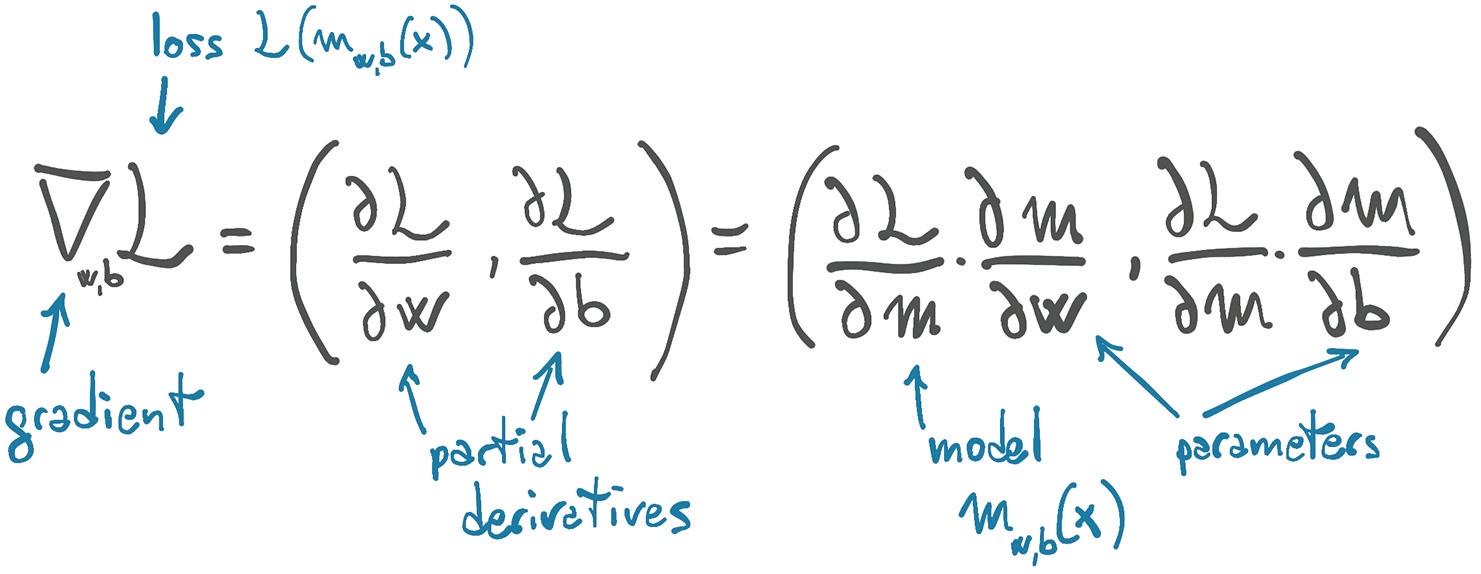

In [9]:
# Loss Function
def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c) ** 2  #--> Derivative of x^2 = 2x
    return squared_diffs.mean()

# Derivative of Loss Funct.
def dloss_fn(t_p, t_c):
    d_sq_diffs = 2 * (t_p - t_c) / t_p.size(0) # / t_p.size(0) is from derivative of mean
    return d_sq_diffs

# Model
def model(t_u, w, b):
    return w * t_u + b

# Derivative of model respect to w
def dmodel_dw(t_u, w, b):
    return t_u

# Derivative of model respect to b
def dmodel_db(t_u, u, b):
    return 1.0

# The function returning the gradient
def grad_fn(t_u, t_c, t_p, w, b):
    dloss_dtp = dloss_fn(t_p, t_c)
    dloss_dw = dloss_dtp * dmodel_dw(t_u, w, b)
    dloss_db = dloss_dtp * dmodel_db(t_u, w, b)
    return torch.stack([dloss_dw.sum(), dloss_db.sum()])  # Torch .stack creates a dynamic tensor where elements can be added. -- The .sum() is to reverse of the broadcasting we do when applying the parameters to vector of inputs in the model.

#### Creating the Training Loop 

- Train the Model: Update parameters by looping through optimisation process \
--> Can loop either a fixed # times or until params stop changing
- **Epochs**: Training itterations where model params are updated

In [22]:
def training_loop(n_epochs, lr, params, t_u, t_c, print_params=True):
    for epoch in range(1, n_epochs +1):
        w, b = params

        t_p = model(t_u, w, b) # Forward Pass
        loss = loss_fn(t_p, t_c) #Used to display loss -- Not really part of training?
        grad = grad_fn(t_u, t_c, t_p, w, b) #Backward Pass

        params = params - lr * grad #Will broadcast and mult grad by lr and then change each respective weight

        # Only print select epochs
        if epoch in {1, 2, 3, 10, 11, 99, 100, 4000, 5000}:
            print('Epoch: %d, Loss %f ' % (epoch, float(loss)))
            if print_params == True:
                print(f'     Params: {params} \n')
                print(f'     Grad: {grad} \n')
        if epoch in {4, 12, 101}:
            print('...')

        if not torch.isfinite(loss).all(): # Breaks loop if loss it inf -- Model Diverges
            break

    return params

Run Training

In [23]:
training_loop(
    n_epochs=100,
    lr= 1e-2,
    params = torch.tensor([1.0, 0.0]),
    t_u = t_u,
    t_c = t_c)

Epoch: 1, Loss 1763.884766 
     Params: tensor([-44.1730,  -0.8260]) 

     Grad: tensor([4517.2964,   82.6000]) 

Epoch: 2, Loss 5802484.500000 
     Params: tensor([2568.4011,   45.1637]) 

     Grad: tensor([-261257.4062,   -4598.9702]) 

Epoch: 3, Loss 19408029696.000000 
     Params: tensor([-148527.7344,   -2616.3931]) 

     Grad: tensor([15109614.0000,   266155.6875]) 

...
Epoch: 10, Loss 90901105189019073810297959556841472.000000 
     Params: tensor([3.2144e+17, 5.6621e+15]) 

     Grad: tensor([-3.2700e+19, -5.7600e+17]) 

Epoch: 11, Loss inf 
     Params: tensor([-1.8590e+19, -3.2746e+17]) 

     Grad: tensor([1.8912e+21, 3.3313e+19]) 



tensor([-1.8590e+19, -3.2746e+17])

In [24]:
#Try again with smaller lr to see if results converge
training_loop(
    n_epochs=100,
    lr= 1e-4,
    params = torch.tensor([1.0, 0.0]),
    t_u = t_u,
    t_c = t_c)

Epoch: 1, Loss 1763.884766 
     Params: tensor([ 0.5483, -0.0083]) 

     Grad: tensor([4517.2964,   82.6000]) 

Epoch: 2, Loss 323.090515 
     Params: tensor([ 0.3623, -0.0118]) 

     Grad: tensor([1859.5493,   35.7843]) 

Epoch: 3, Loss 78.929634 
     Params: tensor([ 0.2858, -0.0135]) 

     Grad: tensor([765.4666,  16.5122]) 

...
Epoch: 10, Loss 29.105247 
     Params: tensor([ 0.2324, -0.0166]) 

     Grad: tensor([1.4803, 3.0544]) 

Epoch: 11, Loss 29.104168 
     Params: tensor([ 0.2323, -0.0169]) 

     Grad: tensor([0.5781, 3.0384]) 

...
Epoch: 99, Loss 29.023582 
     Params: tensor([ 0.2327, -0.0435]) 

     Grad: tensor([-0.0533,  3.0226]) 

Epoch: 100, Loss 29.022667 
     Params: tensor([ 0.2327, -0.0438]) 

     Grad: tensor([-0.0532,  3.0226]) 



tensor([ 0.2327, -0.0438])

Normalising The Gradient
- If diffrent parameter have very dif. ROC, then a learning rate that is appropreate for one param, will be too small or big for the other.
- Instad of having a seperate learning rate for each param (too much and may not scale well), we can normalise the input to ensure grad values have similar magnitiude and that 1 lr will work 

In [10]:
# Normalise input -- There are better ways, but this works here
t_un = 0.1 * t_u

params = training_loop(
    n_epochs=5000,
    lr= 1e-2,  # Set lr back to og. value
    params= torch.tensor([1.0, 0.0]),
    t_u=t_un,
    t_c=t_c)

#Notice that at the end of training the params: weights and bias look like the values needed to convert from deg C to F!

NameError: name 'training_loop' is not defined

#### Visualizing the Data
- Plotting the data should **always** be the first thing you do before creating/training a model 

In [1]:
%matplotlib inline
from matplotlib import pyplot as plt

# Plot t_p against t_c
t_p = model(t_un, *params) # "unpacks" trained parameters from training loop --  equivalent to model(t_un, params[0], params[1])

fig = plt.figure(dpi=600)
plt.xlabel("Temperature (°Fahrenheit)")
plt.ylabel("Temperature (°Celsius)")
plt.plot(t_u.numpy(), t_p.detach().numpy()) # Have to detatch tensor (from grads) before converting to np array
plt.plot(t_u.numpy(), t_c.numpy(), 'o')

NameError: name 'model' is not defined

## PyTorch Autograd

- Pytorch can automatically determine the gradient (of a model) with respect to its input params
- This is becuasue PyTorch Tensors remembers all operations applied to a tensor and can compute gradients for you via automatic differentiation.

Connection to Hand Made Model: \
--> When defining params: w = torch.tensor([1.0, 0.0], requires_grad=True) ([params list: weight, bisas], grad?) \
-- **Tensors are tracked as variables that require gradients.** \
--> When you compute predictions and loss: model = w * x + b, loss = torch.mean((y_pred - y_true) ** 2) \
-- **PyTorch records the operations done to create loss** \
--> Call: loss.backward() \
-- **Automatically applies the chain rule to compute derivatives and create the gradient** \
-- Note: The gradient is an object of the params tensor

In [11]:
# Rewriting the above network using Autograd

def model(t_u, w, b):
    return w * t_u + b

def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c) ** 2
    return squared_diffs.mean()

# Create the parameter Tensor -- With Gradient Tracking
params = torch.tensor([1.0, 0.0], requires_grad=True)

# Compute the loss -- Since tensor reqire grad, PyTorch creates an autograd graph with all the operation done to tensors to get output
loss = loss_fn(model(t_u, *params), t_c)

# Traverses the graph and compute the gradients (using chain rule)
loss.backward()

# Get the gradient of params -- Stored as a Tensor Attribute
params.grad

# Must Zero the gradient before each traning itteration
# -- BACKWARDS ACCUMULATES (adds) TO THE GRAD ATREBUTE, it dossen't just reassign
if params.grad is not None:
    params.grad.zero_()

Training Loop of Autograd Model

In [28]:
def training_loop(n_epochs, learning_rate, params, t_u, t_c):
    for epoch in range(1, n_epochs +1):
        # ALWAYS DO THIS FIRST - But realistically could be called anywhere before .backward()
        if params.grad is not None:
            params.grad.zero_()

        # Forward pass, Compute loss, Determine Gradient
        t_p = model(t_u, *params)
        loss = loss_fn(t_p, t_c)
        loss.backward()

        # Update params bassed on grad
        with torch.no_grad(): # Don't track (add) this opperation (to autograd graph)
            params -= learning_rate * params.grad

        if epoch % 500 == 0:
            print('Epoch %d, Loss %f' % (epoch, float(loss)))

    return params

Run training loop

In [29]:
training_loop(
    n_epochs = 5000,
    learning_rate= 1e-2,
    params= torch.tensor([1.0, 0.0], requires_grad=True),
    t_u= t_un,
    t_c= t_c)

Epoch 500, Loss 7.860115
Epoch 1000, Loss 3.828538
Epoch 1500, Loss 3.092191
Epoch 2000, Loss 2.957698
Epoch 2500, Loss 2.933134
Epoch 3000, Loss 2.928648
Epoch 3500, Loss 2.927830
Epoch 4000, Loss 2.927679
Epoch 4500, Loss 2.927652
Epoch 5000, Loss 2.927647


tensor([  5.3671, -17.3012], requires_grad=True)

- These 20 lines of code do the exact same thing that all the code from the last section did - Just Automatically! \
--> Notice that even params have the same value as above

## Using an Optimiser

- Optimisers Automatically Updates Params and somtimes learing rate deppending on the individual optimiszer arcitecture \
- .step() tells optimizer to update params bassed on their stored gradient
- **Still Have to Zero Gradient after Each Step!** with .zero_grad()
- The SGD (stocastic gradient decent) optimizer does the same as the vanilla gradient decent code above

In [12]:
# Implementing a gradient descent optimiser using torch optim
import torch
import torch.optim as optim

params = torch.tensor([1.0, 0.0], requires_grad=True)
learning_rate = 1e-5

# This does the same thing as Gradient Decent code above
optimizer = optim.SGD([params], lr=learning_rate)

t_p = model(t_u, *params)
loss = loss_fn(t_p, t_c)

optimizer.zero_grad() #MUST ZERO GRAD before calling backward 
loss.backward()
optimizer.step() #
params

tensor([ 9.5483e-01, -8.2600e-04], requires_grad=True)

In [31]:
def training_loop(n_epochs, optimizer, params, t_u, t_c):
    for epoch in range(1, n_epochs + 1):
        t_p = model(t_u, *params)
        loss = loss_fn(t_p, t_c)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            print('Epoch %d, Loss %f' % (epoch, float(loss)))

    return params

In [32]:
# Run Training Loop
params = torch.tensor([1.0, 0.0], requires_grad=True)
lr = 1e-2
optimizer = optim.SGD([params], lr=lr) #Params in optimizer must be same as params in training loop

training_loop(
    n_epochs = 5000,
    optimizer = optimizer,
    params = params,
    t_u = t_un,
    t_c = t_c)

Epoch 500, Loss 7.860120
Epoch 1000, Loss 3.828538
Epoch 1500, Loss 3.092191
Epoch 2000, Loss 2.957698
Epoch 2500, Loss 2.933134
Epoch 3000, Loss 2.928648
Epoch 3500, Loss 2.927830
Epoch 4000, Loss 2.927679
Epoch 4500, Loss 2.927652
Epoch 5000, Loss 2.927647


tensor([  5.3671, -17.3012], requires_grad=True)

Same Thing with Adam Optimizer
- More advanced optimizer where lr is set adaptively
- Less sensative to non-scalled (non-normalized) params / inputs

In [33]:
params = torch.tensor([1.0, 0.0], requires_grad=True)
lr = 1e-1 # Can even use much bigger lr (scaling factor) with Adam
optimizer = optim.Adam([params], lr=lr)

training_loop(
    n_epochs=5000,
    optimizer=optimizer,
    params=params,
    t_u = t_u,  #Notice these are the non-normalised - Og. Values
    t_c = t_c)

Epoch 500, Loss 7.612900
Epoch 1000, Loss 3.086698
Epoch 1500, Loss 2.928578
Epoch 2000, Loss 2.927646
Epoch 2500, Loss 2.927645
Epoch 3000, Loss 2.927646
Epoch 3500, Loss 2.927645
Epoch 4000, Loss 2.927646
Epoch 4500, Loss 2.927646
Epoch 5000, Loss 2.927645


tensor([  0.5368, -17.3048], requires_grad=True)

At the very end, all you really need to define is the model arcetecture, parameters,  loss function, and pick an optimiser
- The rest is more/less done automatically
- Backpropegration with Autograd to estimate Gradients
- Optimiser (like grad. decent) to update parameters (and lr)

## Avoiding Overfitting

- Models can get very good at making predictions on the training set, but not generalize and make accurate predictions to any new data
- To Fix this: Seperate Dataset Into Training and Validation, and then shuffle dataset

- Rule 1: if the training loss is not decreasing, chances are the
model is too simple for the data.
- Rule 2: if the training loss and the validation loss
diverge, we’re overfitting.
- To choose right size for Neural Network: Increase size until it fits the data, then decrease size until it stops overfitting

In [43]:
# Spliting data
n_samples = t_u.shape[0]
n_val = int(0.2 * n_samples) #Seperate 20% of samples for validataion

# Shuffling Data
shuffled_indices = torch.randperm(n_samples) # Creates randomly ordered list of indecies of sizd n_samples
train_indecies = shuffled_indices[:-n_val] # Indecies for train dataset
val_indecies = shuffled_indices[-n_val:] # Indecies for val dataset

train_indecies, val_indecies

(tensor([ 2,  4, 10,  5,  0,  9,  8,  7,  1]), tensor([3, 6]))

In [13]:
# Apply the split and shuffle to dataset - Done this way to make sure input and ground truth entries match
train_t_u = t_u[train_indecies]
train_t_c = t_c[train_indecies]

val_t_u = t_u[val_indecies]
val_t_c = t_c[val_indecies]

# Normalise data
train_t_un = 0.1 *train_t_u
val_t_un = 0.1 * val_t_u

NameError: name 'train_indecies' is not defined

Running Data Through Model - same thing, just additionally checking loss on val at each epoch

In [141]:
def training_loop(n_epochs, optimizer, params, train_t_u, val_t_u, train_t_c, val_t_c):
    for epoch in range(1, n_epochs + 1):
        train_t_p = model(train_t_u, *params)
        train_loss = loss_fn(train_t_p, train_t_c)
        
        # Switch off Autograd for val dataset - No need to build computation graph
        with torch.no_grad(): 
            val_t_p = model(val_t_u, *params)
            val_loss = loss_fn(val_t_p, val_t_c)
            assert val_loss.requires_grad == False #Makes sure require grad is false. if not, throw an error
        
        optimizer.zero_grad()
        train_loss.backward() #Remember, we don't train on val data
        optimizer.step()

        if epoch <= 3 or epoch % 1000 == 0:
            print(f'Epoch {epoch}: Training Loss: {train_loss.item():.4f}, \
                Validation Lost: {val_loss.item():.4f}')

    return params
        

In [142]:
params = torch.tensor([1.0, 0.0], requires_grad=True)
lr = 1e-2
optimizer = optim.Adam([params], lr=lr)

training_loop(
    n_epochs= 5000,
    optimizer= optimizer,
    params= params,
    train_t_u= train_t_un,
    val_t_u= val_t_un,
    train_t_c= train_t_c,
    val_t_c= val_t_c)


Epoch 1: Training Loss: 98.0567,                 Validation Lost: 0.7488
Epoch 2: Training Loss: 96.9936,                 Validation Lost: 0.7009
Epoch 3: Training Loss: 95.9397,                 Validation Lost: 0.6583
Epoch 1000: Training Loss: 17.8593,                 Validation Lost: 18.2932
Epoch 2000: Training Loss: 6.5630,                 Validation Lost: 7.9108
Epoch 3000: Training Loss: 2.8473,                 Validation Lost: 5.5823
Epoch 4000: Training Loss: 2.2758,                 Validation Lost: 5.9208
Epoch 5000: Training Loss: 2.2517,                 Validation Lost: 6.1352


tensor([  5.4729, -17.8086], requires_grad=True)

In [ ]:
# Set whether autograd is enabled or disabled basses on bool
def calc_forward(t_u, t_c, is_train):
    with torch.set_grad_enabled(is_train):
        t_p = model(t_u, *params)
        loss = loss_fn(t_p, t_c)
    return loss

Note: Torch.no_grad() dosen't neccesarilly mean no gradients. \
It just dosen't create a graph for autgrad. 
To ensure no gradients use the .detatch() funtion on the tensor \
Side note: This model dosen't really accuratly convert F to C, because the data it was trained on is not accurate and a small range. Instead it does the best conversion it can, giving a ballpark answer

In [157]:
temp_f = [0, 32]

for f in temp_f:
    c = model(f, *params)
    print(f'Deg F: {f}, Pred Deg C: {c}')

#The first pred. is very accurate, While the seccond is not even close
# Using a larger/better models, we can do better --> Ch 6!

Deg F: 0, Pred Deg C: -17.808616638183594
Deg F: 32, Pred Deg C: 157.32339477539062


# Excersie

Redefine the model to be w2 * t_u ** 2 + w1 * t_u + b. 
- What parts of the training loop, and so on, need to change to accommodate this redefinition?
- What parts are agnostic to swapping out the model?
- Is the resulting loss higher or lower after training?
- Is the actual result better or worse?

a. Almost nothing needs to chnage, apart from the params to reacomedate --> gradients and param update are handeled by autograd and optim \
b. The parts agnostic to swapping the model is the loss fn \
c. The resulting loss is higher \
d. The actual loss is much higher --> Overfitting \
--> Reason for c, d is that deg_f to deg_c (or really any temp conversion) is linear, and so using a quadratic model won't fit the data

In [63]:
import torch
import torch.optim as optim

def model(input_data, w2, w1, b):
    prediction = w2 * input_data ** 2 + w1 * input_data + b
    return prediction

def loss_fn(prediction, ground_truth):
    loss = (prediction - ground_truth) ** 2
    return loss.mean()

def training_loop(n_epochs, optimizer, params, input_data, ground_truth, validation_data, validation_truth):
    for epoch in range(1, n_epochs + 1):
        train_prediction = model(input_data, *params)
        train_loss = loss_fn(train_prediction, ground_truth)

        with torch.no_grad():
            val_prediction = model(validation_data, *params)
            val_loss = loss_fn(val_prediction, validation_truth)
            assert val_loss.requires_grad == False #Makes sure require grad is false. if not, throw an error
        
        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        if epoch <= 3 or epoch % 1000 == 0:
            print(f'EPOCH {epoch}: Training Loss {train_loss}, Validation Loss {val_loss}')
    
    return params

In [81]:
parmas = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)
lr = 1e-1

optimizer = optim.Adam([parmas], lr=lr)

params = training_loop(n_epochs=5000,
              optimizer=optimizer,
              params=parmas,
              input_data=train_t_un,
              ground_truth=train_t_c,
             validation_data=val_t_un,
             validation_truth=val_t_c)

EPOCH 1: Training Loss 562.052001953125, Validation Loss 1187.6348876953125
EPOCH 2: Training Loss 406.4961853027344, Validation Loss 838.627197265625
EPOCH 3: Training Loss 277.48748779296875, Validation Loss 552.289794921875
EPOCH 1000: Training Loss 1.6033329963684082, Validation Loss 23.03955841064453
EPOCH 2000: Training Loss 1.570488691329956, Validation Loss 19.923887252807617
EPOCH 3000: Training Loss 1.5575138330459595, Validation Loss 17.579755783081055
EPOCH 4000: Training Loss 1.5557729005813599, Validation Loss 16.594655990600586
EPOCH 5000: Training Loss 1.5557239055633545, Validation Loss 16.41341781616211


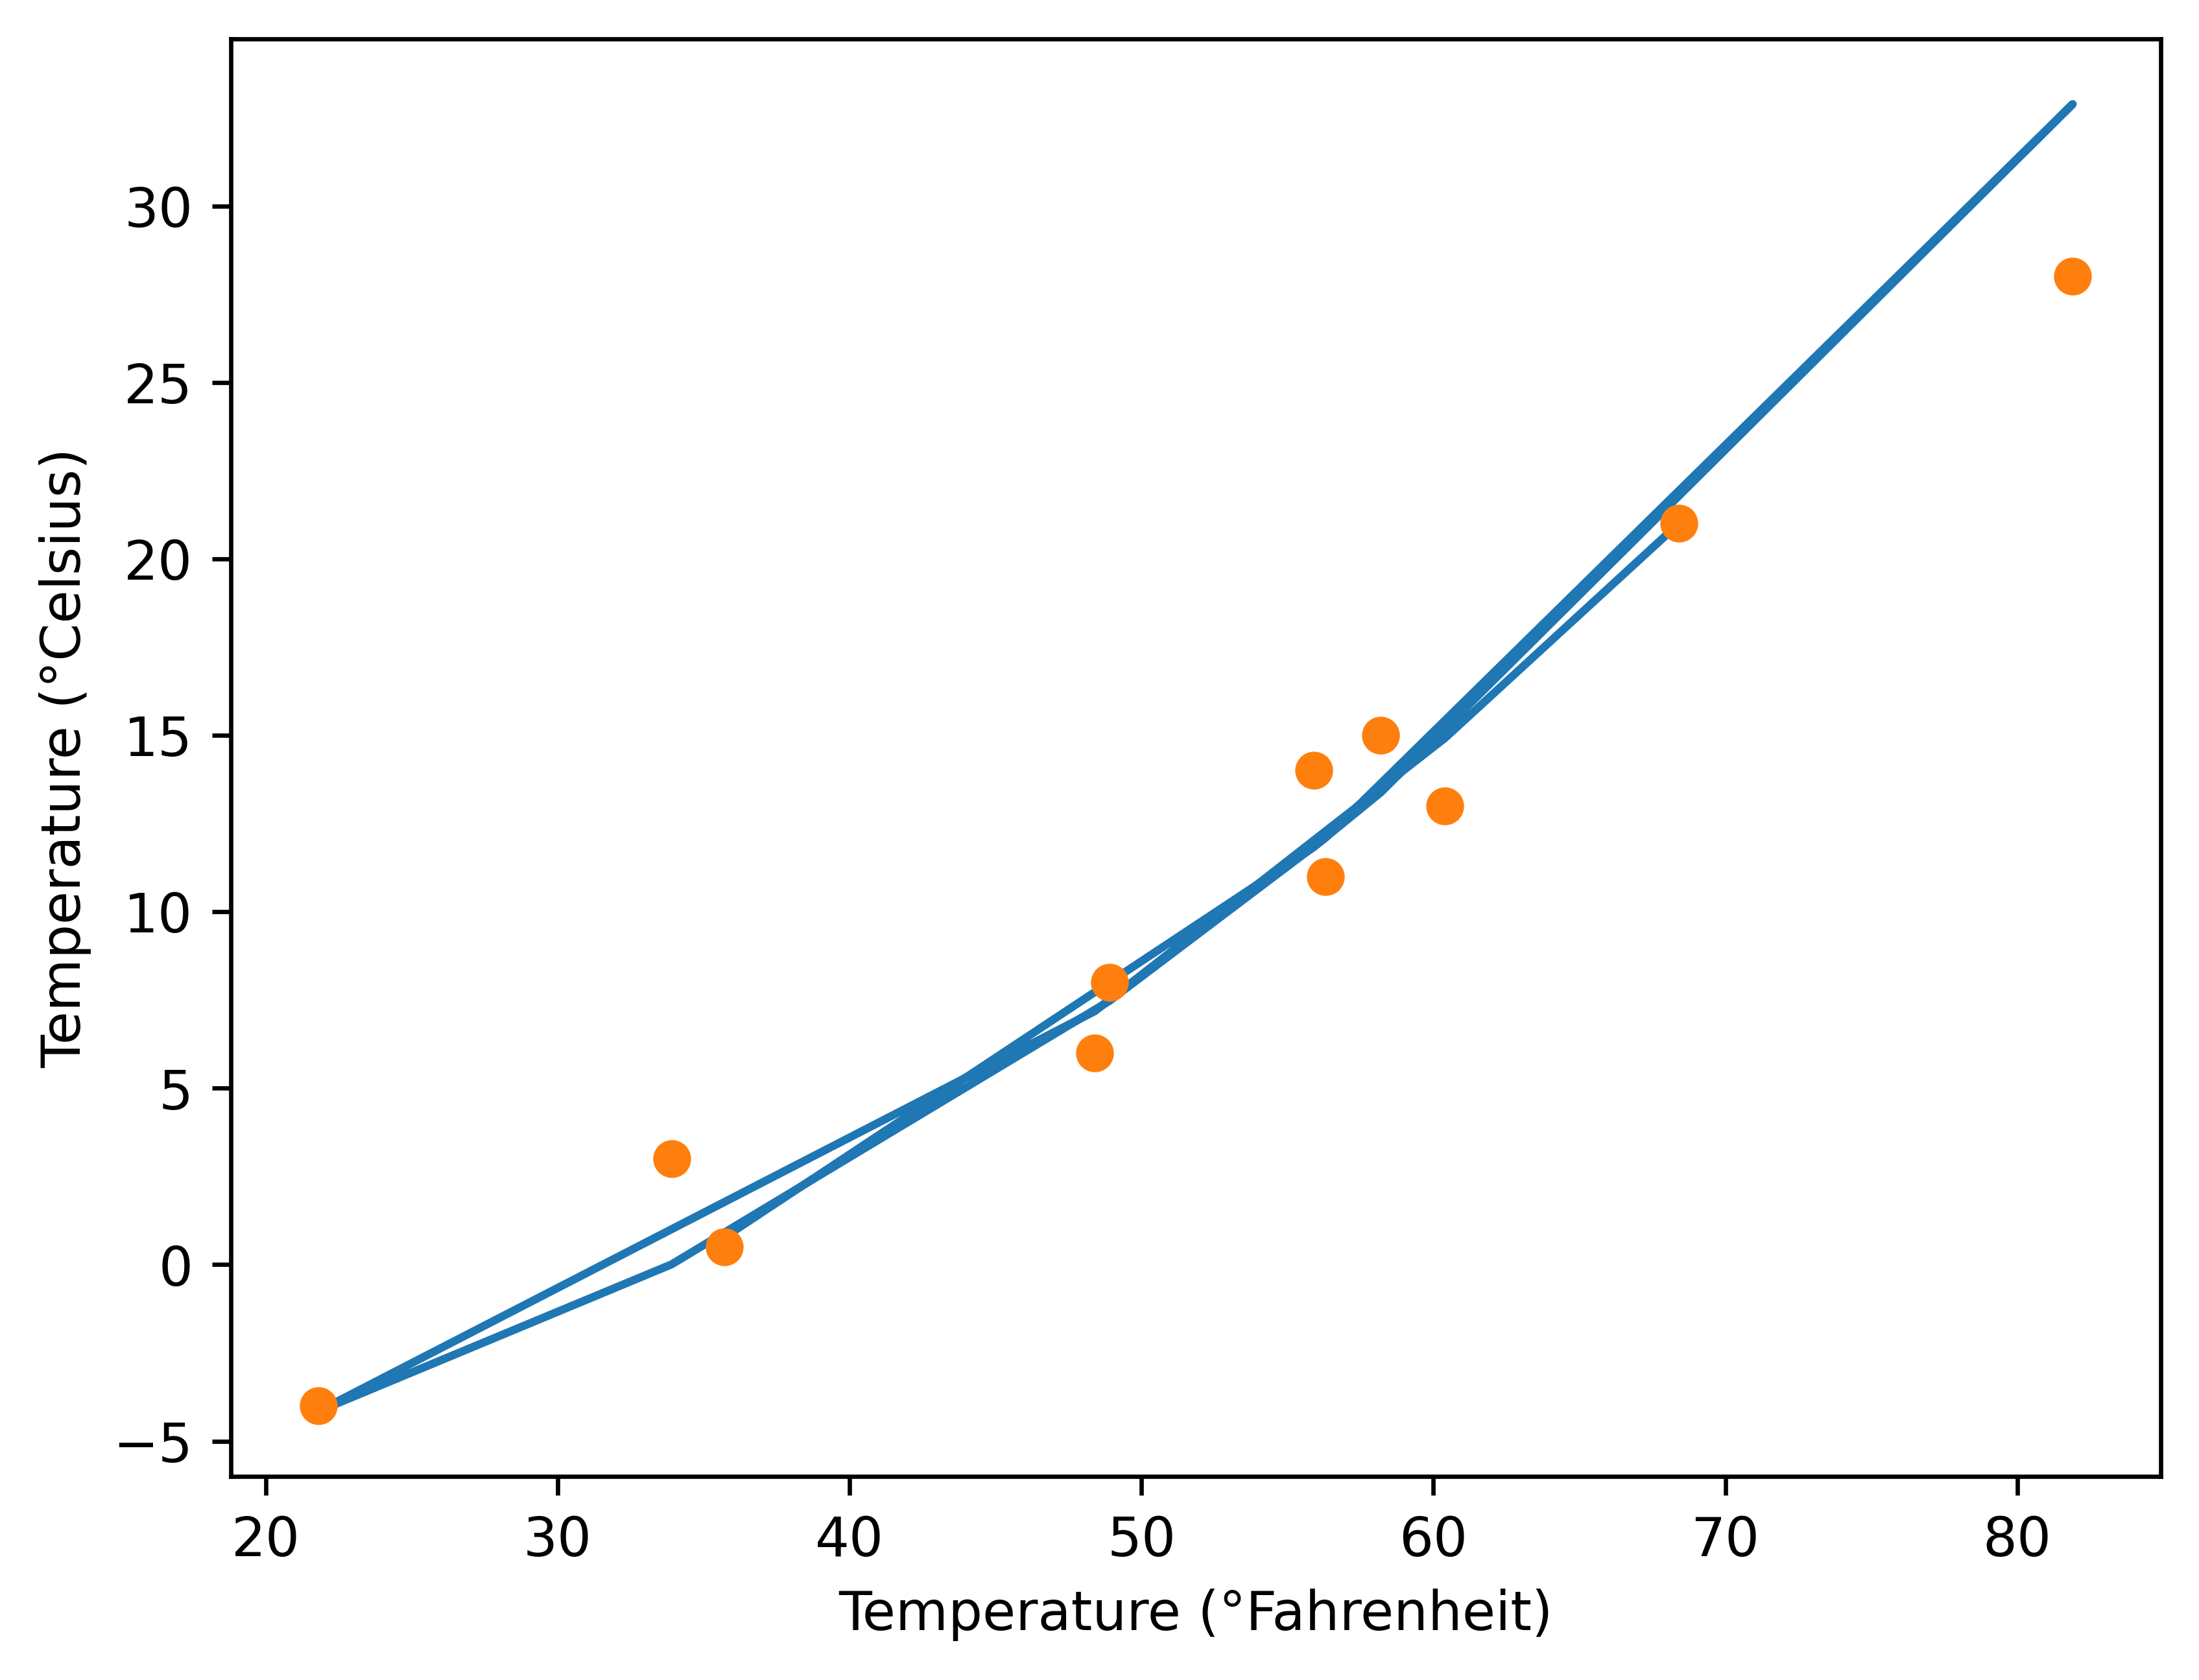

In [84]:
%matplotlib inline
from matplotlib import pyplot as plt

# Plot t_p against t_c
t_p = model(t_un, *params) # "unpacks" trained parameters from training loop --  equivalent to model(t_un, params[0], params[1])

fig = plt.figure(dpi=600)
plt.xlabel("Temperature (°Fahrenheit)")
plt.ylabel("Temperature (°Celsius)")
plt.plot(t_u.numpy(), t_p.detach().numpy()) # Have to detatch tensor (from grads) before converting to np array
plt.plot(t_u.numpy(), t_c.numpy(), 'o')